# Transaction Anomaly Lab: Validation Extension

This notebook extends the existing rithmsAI project. All observations are fictional. Anomaly scores are not fraud probabilities.

## 1. Inspect the data and imbalance
Do this before fitting. The label is a simulator label. It cannot establish real fraud detection performance.

In [1]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
if not (root/'lab.py').exists(): root=root.parent
assert (root/'lab.py').exists()
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display,Image
from lab import generate,FEATURES,run
x,y=generate(3000,44)
frame=pd.DataFrame(x,columns=FEATURES)
display(frame.describe())
display(frame.isna().sum().to_frame('missing'))
print('Synthetic anomaly prevalence:', y.mean())
print('Accuracy if every event is called normal:', 1-y.mean())

,amount_usd,distance_km,transactions_last_hour,account_age_days
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,84.644379,34.841773,2.103333,586.146474
std,198.147614,67.565520,1.712591,601.241296
min,1.095946,0.007752,0.000000,0.144966
25%,19.569319,8.586505,1.000000,156.714777
50%,42.158485,20.893637,2.000000,401.484042
75%,89.367065,43.064716,3.000000,819.120763
max,7487.300130,1953.801835,18.000000,4461.499804


,missing
amount_usd,0
distance_km,0
transactions_last_hour,0
account_age_days,0


Synthetic anomaly prevalence: 0.037333333333333336
Accuracy if every event is called normal: 0.9626666666666667


## 2. Run the existing baseline
Fit only training features; select thresholds on calibration scores without labels; evaluate once on held-out labels. The generator lacks timestamps/accounts, so temporal/entity validation is not claimed.

,average_precision,precision,recall,alert_rate,true_positives,false_positives,false_negatives,true_negatives,threshold
Rules baseline,0.649330,0.482143,0.723214,0.056000,81.0,87.0,31.0,2801.0,0.938049
Isolation Forest,0.523441,0.398773,0.580357,0.054333,65.0,98.0,47.0,2790.0,0.562880


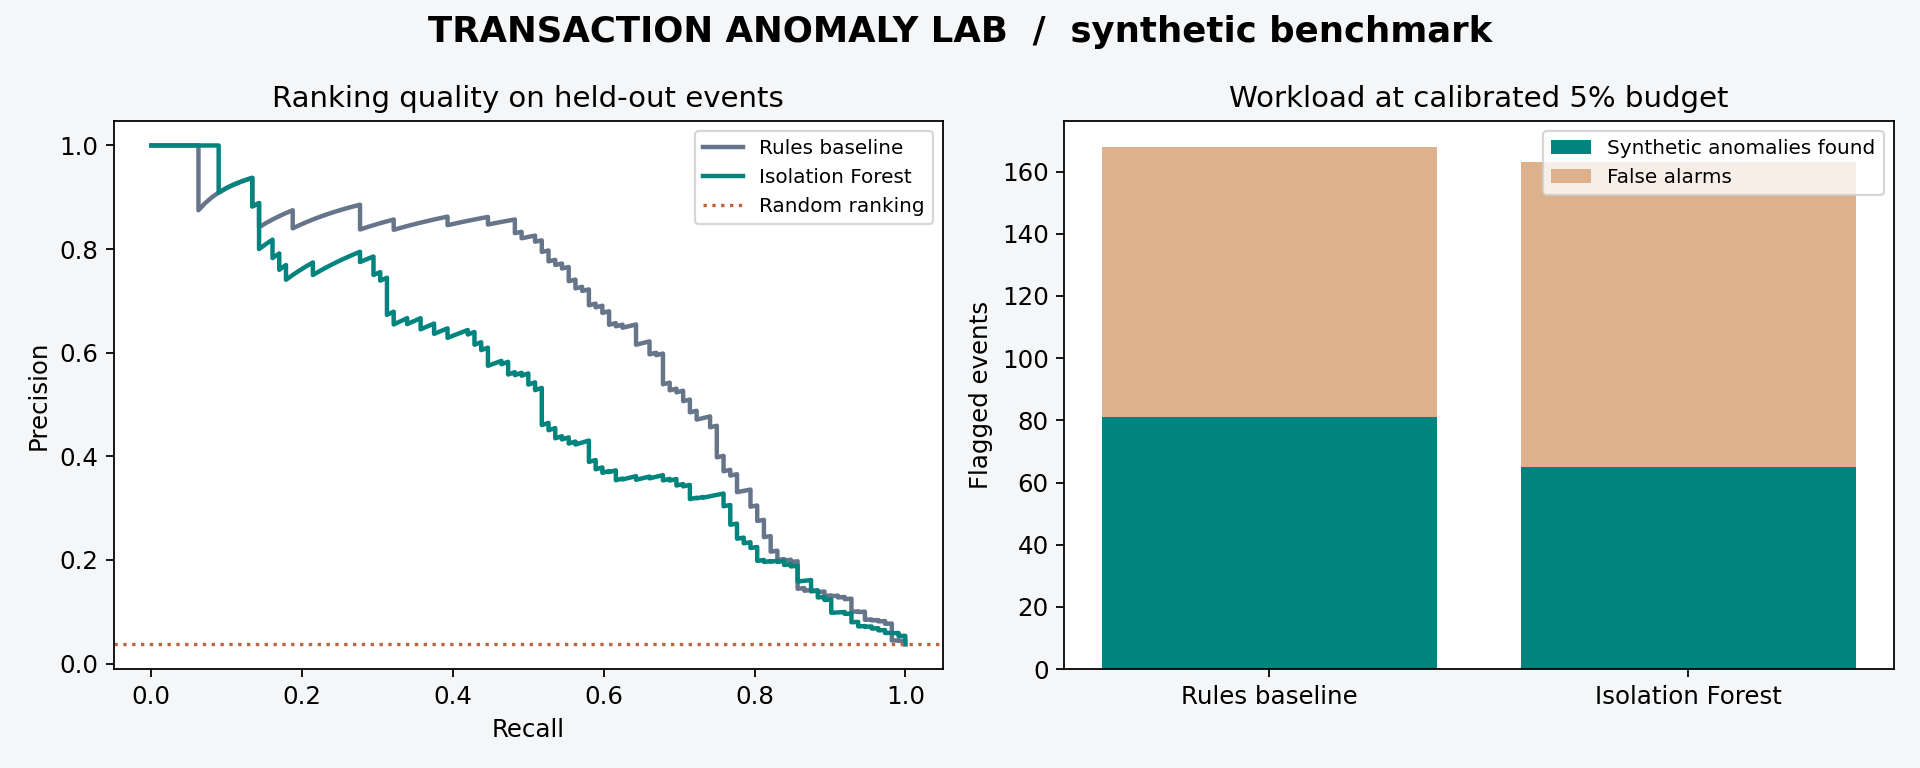

In [2]:
result=run(root/'reports/notebook_baseline')
display(pd.DataFrame(result['models']).T)
display(Image(filename=str(root/'reports/notebook_baseline/benchmark.png')))

## 3. Add robustness and uncertainty
Separated seed triplets avoid reusing the same random streams across runs. AP lift references rare-class prevalence. The paired stratified bootstrap compares rankings on the same resampled rows; its interval is conditional on the fitted model and class mix.

In [3]:
from validation_audit import run as audit
audit_result=audit(root/'reports/validation_audit.json')
rows=[]
for item in audit_result['runs']:
    for name,metrics in item['models'].items():
        rows.append({'seed':item['seed'],'model':name,'prevalence':item['prevalence'],**metrics})
display(pd.DataFrame(rows)[['seed','model','average_precision','ap_lift_over_prevalence','precision','recall','false_positives','alert_rate']])
display(pd.DataFrame([{'seed':r['seed'],'rules_minus_ml_ap_interval':r['paired_rules_minus_ml_ap_95pct_bootstrap']} for r in audit_result['runs']]))

,seed,model,average_precision,ap_lift_over_prevalence,precision,recall,false_positives,alert_rate
0,42,rules,0.649330,17.392762,0.482143,0.723214,87,0.056000
1,42,isolation_forest,0.523441,14.020745,0.398773,0.580357,98,0.054333
2,142,rules,0.701054,17.098882,0.615385,0.715447,55,0.047667
3,142,isolation_forest,0.524921,12.802958,0.482993,0.577236,76,0.049000
4,242,rules,0.670871,20.536858,0.513889,0.755102,70,0.048000
5,242,isolation_forest,0.435214,13.322868,0.344828,0.612245,114,0.058000
6,342,rules,0.737783,18.917523,0.580645,0.769231,65,0.051667
7,342,isolation_forest,0.496947,12.742222,0.454545,0.598291,84,0.051333
8,442,rules,0.687730,16.374513,0.637681,0.698413,50,0.046000
9,442,isolation_forest,0.514342,12.246233,0.516393,0.500000,59,0.040667


,seed,rules_minus_ml_ap_interval
0,42,"[0.05594543893370614, 0.19920189630905485]"
1,142,"[0.10060514877070668, 0.24242665434609917]"
2,242,"[0.15318745193995048, 0.30539103069114615]"
3,342,"[0.15915581056303937, 0.3202638451551852]"
4,442,"[0.09781120906632099, 0.24548516079961571]"


## 4. Explain the tests and limits
New tests reject invalid evaluation inputs, verify training-only fit, and check test-label changes cannot alter calibration thresholds. Original tests cover API and persistence behavior. Rules share assumptions with the simulator, so their advantage is not a real-world claim. Review docs/SIS310_EXTENSION.md for the future chronological/entity validation contract and safe API/SQL use.